# 🚀 Masterclass: Ensemble Learning & Explainable AI (XAI)
## Random Forest, Extra Trees, AdaBoost, Gradient Boosting, XGBoost, PDP & SHAP

---

### 📌 Module Roadmap
1. **Bagging vs. Boosting**: Core philosophies, mathematical mechanisms & Bias-Variance tradeoff
2. **Random Forest & Extra Trees**: Extreme randomization, Out-of-Bag (OOB) estimation, speed vs variance
3. **AdaBoost (Adaptive Boosting)**: Exponential loss, sample weight updates, weak learner aggregation
4. **Gradient Boosting Decision Trees (GBDT)**: Residual learning, pseudo-residuals, learning rate (shrinkage)
5. **XGBoost (Extreme Gradient Boosting)**: 2nd-order Taylor expansion (gradients & hessians), $L_1/L_2$ regularization, missing value handling
6. **Overfitting Analysis & Hyperparameter Defense**: Tree depth, subsampling, shrinkage, early stopping
7. **Feature Importance Deep-Dive**: MDI (Mean Decrease in Impurity) vs. Permutation Feature Importance
8. **Industry Decision Matrix**: When to choose which ensemble architecture
9. **Model Explainability with Partial Dependence Plots (PDP)**: 1D marginal effects & 2D interaction plots
10. **Explainable AI with SHAP (SHapley Additive exPlanations)**: Game theory, TreeExplainer, Beeswarm, Waterfall & Force plots


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, confusion_matrix
from sklearn.inspection import PartialDependenceDisplay, partial_dependence, permutation_importance

# Ensemble Models
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)
from xgboost import XGBClassifier

# Explainable AI
import shap

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100

print("✅ All ensemble modeling and XAI (SHAP, PDP) libraries loaded successfully.")


✅ All ensemble modeling and XAI (SHAP, PDP) libraries loaded successfully.


## 📂 Section 1: Benchmark Dataset Preparation
We utilize the **Breast Cancer Wisconsin Diagnostic Dataset** (569 samples, 30 continuous features). It represents a high-stakes clinical classification problem where both **high predictive accuracy** and **transparent model explainability** are mandatory.


In [2]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name='malignant_or_benign')

# Clean feature names for clean plotting
X.columns = [col.replace(' ', '_') for col in X.columns]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"Training shape: {X_train.shape}, Test shape: {X_test.shape}")
print(f"Class distribution in training: Malignant (0): {(y_train==0).sum()}, Benign (1): {(y_train==1).sum()}")
X_train.head(3)


Training shape: (426, 30), Test shape: (143, 30)
Class distribution in training: Malignant (0): 159, Benign (1): 267


,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,mean_fractal_dimension,...,worst_radius,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension
517,19.89,20.26,130.50,1214.0,0.10370,0.13100,0.1411,0.09431,0.1802,0.06188,...,23.73,25.23,160.5,1646.0,0.14170,0.3309,0.4185,0.16130,0.2549,0.09136
287,12.89,13.12,81.89,515.9,0.06955,0.03729,0.0226,0.01171,0.1337,0.05581,...,13.62,15.54,87.4,577.0,0.09616,0.1147,0.1186,0.05366,0.2309,0.06915
25,17.14,16.40,116.00,912.7,0.11860,0.22760,0.2229,0.14010,0.3040,0.07413,...,22.25,21.40,152.4,1461.0,0.15450,0.3949,0.3853,0.25500,0.4066,0.10590


## 🧠 Section 2: Bagging vs. Boosting — Theoretical Foundations

```
                            ┌────────────────────────────────────────┐
                            │       Ensemble Learning Paradigms      │
                            └───────────────────┬────────────────────┘
                                                │
                 ┌──────────────────────────────┴──────────────────────────────┐
                 ▼                                                             ▼
     [BAGGING (Bootstrap Aggregating)]                             [BOOSTING (Sequential Boosting)]
     - Base learners trained IN PARALLEL                           - Base learners trained SEQUENTIALLY
     - Independent bootstrap samples                               - Each model corrects errors of previous models
     - Aggregation via Majority Vote / Average                     - Aggregation via Weighted Sum
     - Primary Goal: REDUCE VARIANCE (combat overfitting)          - Primary Goal: REDUCE BIAS (combat underfitting)
     - Base models: Deep, high-variance trees                      - Base models: Shallow, high-bias trees (stumps)
     - Examples: Random Forest, Extra Trees                        - Examples: AdaBoost, Gradient Boosting, XGBoost
```

### 📐 The Bias-Variance Decomposition:
$$\text{Expected Loss} = \text{Bias}^2 + \text{Variance} + \text{Irreducible Noise}$$
- **Bagging**: Averaging $B$ independent models each with variance $\sigma^2$ and pairwise correlation $\rho$:
  $$\text{Var}(\bar{f}) = \rho \sigma^2 + \frac{1 - \rho}{B} \sigma^2$$
  As $B \to \infty$, the second term drops to 0, leaving $\rho \sigma^2$. To minimize total variance, Bagging **de-correlates** the trees!
- **Boosting**: Builds an additive model $\hat{y}_M(x) = \sum_{m=1}^M \eta \cdot h_m(x)$, where each weak learner $h_m$ fits the pseudo-residuals of the current ensemble, systematically driving bias to zero.


## 🌲 Section 3: Random Forest vs. Extremely Randomized Trees (Extra Trees)

### 1. Random Forest (Breiman, 2001)
- **Double Randomization**:
  1. **Row Sampling**: Each tree is trained on a bootstrap sample (random sampling with replacement, capturing ~63.2% of unique rows).
  2. **Feature Sampling**: At each split, only a random subset of features $m = \sqrt{p}$ is considered.
- **Out-Of-Bag (OOB) Estimation & Mathematical Derivation**:
  - Probability of selecting sample $i$ in 1 draw: $P(\text{hit}) = \frac{1}{n}$
  - Probability of NOT selecting sample $i$ in 1 draw: $P(\text{miss}) = 1 - \frac{1}{n}$
  - Across all $n$ independent draws with replacement:
    $$P(\text{Instance } i \text{ is OOB}) = \left(1 - \frac{1}{n}\right)^n \xrightarrow{n \to \infty} \frac{1}{e} \approx 36.79\%$$
  - **Mechanics of OOB Evaluation**: The remaining ~36.8% unselected samples for each tree act as an **internal validation set**. For instance $i$, an ensemble prediction is formed using **only** the trees where instance $i$ was out-of-bag:
    $$\hat{P}^{OOB}(Y = c \mid x_i) = \frac{1}{|\mathcal{B}_i^{OOB}|} \sum_{b \in \mathcal{B}_i^{OOB}} I(\hat{y}_{i, b} = c)$$
  - **Zero Compute Waste**: Leo Breiman proved that OOB error is an unbiased estimator of generalization error asymptotically equivalent to Leave-One-Out Cross-Validation (LOOCV), eliminating the need to train $K$ separate models during CV!

### 2. Extra Trees (Geurts et al., 2006)
- Takes randomization a step further:
  1. Uses the **entire training dataset** (no bootstrapping by default).
  2. For each candidate feature, instead of searching for the mathematically optimal threshold (via Gini/Entropy minimization), it picks cutoffs **completely at random** and chooses the best among them!
- **Result**: Drastically faster training speed and lower variance at the cost of slightly higher bias.


In [3]:
# Train Random Forest with Out-Of-Bag (OOB) Evaluation
rf_clf = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    max_features='sqrt',
    oob_score=True,
    random_state=42
)
rf_clf.fit(X_train, y_train)

# Train Extra Trees Classifier
et_clf = ExtraTreesClassifier(
    n_estimators=100,
    max_depth=5,
    max_features='sqrt',
    bootstrap=False,
    random_state=42
)
et_clf.fit(X_train, y_train)

# Calculate OOB ROC-AUC from oob_decision_function_
oob_roc_auc = roc_auc_score(y_train, rf_clf.oob_decision_function_[:, 1])

print(f"🌲 Random Forest OOB Accuracy Score: {rf_clf.oob_score_*100:.2f}% (OOB ROC-AUC: {oob_roc_auc:.4f})")
print(f"🌲 Random Forest Test Accuracy:     {accuracy_score(y_test, rf_clf.predict(X_test))*100:.2f}% (ROC-AUC: {roc_auc_score(y_test, rf_clf.predict_proba(X_test)[:,1]):.4f})")
print(f"⚡ Extra Trees Test Accuracy:       {accuracy_score(y_test, et_clf.predict(X_test))*100:.2f}% (ROC-AUC: {roc_auc_score(y_test, et_clf.predict_proba(X_test)[:,1]):.4f})")


🌲 Random Forest OOB Accuracy Score: 95.31% (OOB ROC-AUC: 0.9841)
🌲 Random Forest Test Accuracy:     95.10% (ROC-AUC: 0.9933)
⚡ Extra Trees Test Accuracy:       95.10% (ROC-AUC: 0.9922)


In [4]:
# Inspect sample-level Out-of-Bag (OOB) Decision Function probabilities
oob_sample_df = pd.DataFrame({
    'True_Class': ['Malignant' if y == 1 else 'Benign' for y in y_train[:8]],
    'OOB_Prob_Malignant': np.round(rf_clf.oob_decision_function_[:8, 1], 4),
    'OOB_Predicted': ['Malignant' if p >= 0.5 else 'Benign' for p in rf_clf.oob_decision_function_[:8, 1]]
})
oob_sample_df['Is_Correct'] = oob_sample_df['True_Class'] == oob_sample_df['OOB_Predicted']
print("📦 Out-of-Bag (OOB) Prediction Inspection (First 8 Training Observations):")
display(oob_sample_df)


📦 Out-of-Bag (OOB) Prediction Inspection (First 8 Training Observations):


,True_Class,OOB_Prob_Malignant,OOB_Predicted,Is_Correct
0,Benign,0.0000,Benign,True
1,Malignant,0.9981,Malignant,True
2,Benign,0.0021,Benign,True
3,Benign,0.0062,Benign,True
4,Benign,0.0002,Benign,True
5,Benign,0.1950,Benign,True
6,Malignant,0.9955,Malignant,True
7,Benign,0.0984,Benign,True


## ⚡ Section 4: Boosting Architectures — AdaBoost, GBDT & XGBoost

### 1. AdaBoost (Adaptive Boosting)
- Minimizes **Exponential Loss**: $L(y, f(x)) = \exp(-y \cdot f(x))$.
- In each round $m$:
  1. Fits a weak learner (Decision Stump, `max_depth=1`).
  2. Computes weighted error $\epsilon_m$ and model weight $\alpha_m = \frac{1}{2} \ln\left(\frac{1 - \epsilon_m}{\epsilon_m}\right)$.
  3. Increases weights of misclassified instances: $w_i \leftarrow w_i \exp(\alpha_m)$ so subsequent learners focus on hard examples.

### 2. Gradient Boosting Decision Trees (GBDT)
- Generalizes boosting to **any differentiable loss function** (e.g. Log-Loss, MSE, Huber).
- Instead of reweighting points, each tree fits the **negative gradient** (pseudo-residuals):
  $$r_{im} = -\left[\frac{\partial L(y_i, f(x_i))}{\partial f(x_i)}\right]_{f(x) = f_{m-1}(x)}$$
- Shrinkage (Learning Rate $\eta$): Updates $f_m(x) = f_{m-1}(x) + \eta \cdot h_m(x)$ to prevent overfitting.

### 3. XGBoost (Extreme Gradient Boosting - Chen & Guestrin, 2016)
- **Key Enhancements over GBDT**:
  1. **Second-Order Taylor Approximation**: Uses both 1st derivative (gradient $g_i$) and 2nd derivative (hessian $h_i$) for faster, more accurate split finding.
  2. **Built-in Regularization**: Loss includes penalty on leaf weights:
     $$\Omega(f) = \gamma T + \frac{1}{2} \lambda \sum_{j=1}^T w_j^2 + \alpha \sum_{j=1}^T |w_j|$$
  3. **Sparsity-Aware Split Finding**: Automatically learns optimal default direction for missing values.
  4. **Weighted Quantile Sketch & Column Subsampling**: Parallelized, histogram-accelerated training.


In [5]:
# 1. AdaBoost
ada_clf = AdaBoostClassifier(n_estimators=80, learning_rate=0.1, random_state=42)
ada_clf.fit(X_train, y_train)

# 2. Gradient Boosting
gb_clf = GradientBoostingClassifier(n_estimators=80, learning_rate=0.1, max_depth=3, random_state=42)
gb_clf.fit(X_train, y_train)

# 3. XGBoost
xgb_clf = XGBClassifier(
    n_estimators=80,
    learning_rate=0.1,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    eval_metric='logloss',
    random_state=42
)
xgb_clf.fit(X_train, y_train)

models = {
    'Random Forest': rf_clf,
    'Extra Trees': et_clf,
    'AdaBoost': ada_clf,
    'Gradient Boosting': gb_clf,
    'XGBoost': xgb_clf
}

benchmark_results = []
for name, m in models.items():
    preds = m.predict(X_test)
    probs = m.predict_proba(X_test)[:, 1]
    benchmark_results.append({
        'Model': name,
        'Paradigm': 'Bagging' if name in ['Random Forest', 'Extra Trees'] else 'Boosting',
        'Test Accuracy (%)': round(accuracy_score(y_test, preds) * 100, 2),
        'ROC-AUC': round(roc_auc_score(y_test, probs), 4)
    })

pd.DataFrame(benchmark_results).sort_values(by='ROC-AUC', ascending=False).reset_index(drop=True)


,Model,Paradigm,Test Accuracy (%),ROC-AUC
0,XGBoost,Boosting,97.2,0.9954
1,Random Forest,Bagging,95.1,0.9933
2,Extra Trees,Bagging,95.1,0.9922
3,Gradient Boosting,Boosting,95.8,0.9920
4,AdaBoost,Boosting,95.8,0.9912


## 🎯 Section 5: Overfitting Dynamics & Feature Importance
Ensemble algorithms have distinct overfitting behaviors:
- **Random Forest**: Adding more trees **never overfits**! The generalization error converges to a theoretical upper bound (variance decreases asymptotically). However, excessively deep trees (`max_depth=None`) with small sample size can memorize noise.
- **Boosting**: Adding too many trees **WILL overfit**! Because boosting iteratively corrects remaining errors, it eventually fits noise/outliers unless constrained by **learning rate ($\eta$)** and **early stopping**.

---
### 🔍 Mean Decrease in Impurity (MDI) vs. Permutation Importance:
- **MDI (Gini Importance)**: Measures total impurity reduction brought by a feature across all trees.
  - ⚠️ *Flaw*: Biased toward high-cardinality features or continuous variables with many unique values!
- **Permutation Importance**: Shuffles feature values in the validation set and measures the drop in model performance.
  - ✅ *Advantage*: Completely model-agnostic, unbiased, and reflects true predictive utility on unseen data.


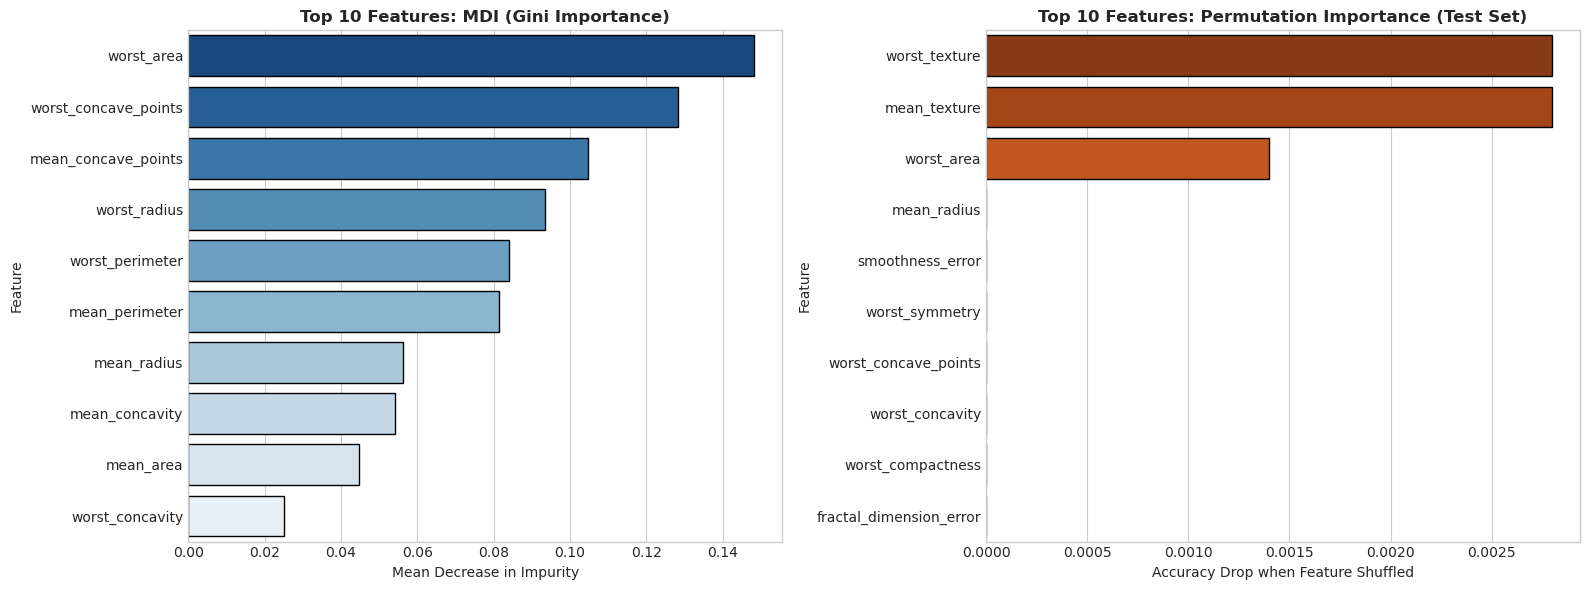

In [6]:
# Comparison of MDI vs Permutation Importance
perm_importance = permutation_importance(rf_clf, X_test, y_test, n_repeats=5, random_state=42)

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'MDI_Importance': rf_clf.feature_importances_,
    'Permutation_Importance_Mean': perm_importance.importances_mean
}).sort_values(by='Permutation_Importance_Mean', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top_mdi = importance_df.sort_values(by='MDI_Importance', ascending=False).head(10)
sns.barplot(x='MDI_Importance', y='Feature', data=top_mdi, ax=axes[0], palette='Blues_r', edgecolor='black')
axes[0].set_title('Top 10 Features: MDI (Gini Importance)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Mean Decrease in Impurity')

top_perm = importance_df.head(10)
sns.barplot(x='Permutation_Importance_Mean', y='Feature', data=top_perm, ax=axes[1], palette='Oranges_r', edgecolor='black')
axes[1].set_title('Top 10 Features: Permutation Importance (Test Set)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Accuracy Drop when Feature Shuffled')

plt.tight_layout()
plt.show()


## 📊 Section 6: When Each Model is Useful — Industry Decision Matrix

| Model | Primary Paradigm | Training Speed | Resilience to Noise | Hyperparameter Sensitivity | Best Use Case |
|---|---|---|---|---|---|
| **Random Forest** | Bagging | Fast (Parallelizable) | High (Robust to outliers) | Low (Good out-of-the-box defaults) | General baseline, datasets where overfitting is a primary concern. |
| **Extra Trees** | Bagging (Extremely Randomized) | Very Fast | High | Low | High-dimensional data where training speed is critical; smooth decision boundaries. |
| **AdaBoost** | Boosting | Moderate (Sequential) | Low (Prone to fitting outliers) | Moderate | Binary classification on clean, structured datasets with low noise. |
| **Gradient Boosting** | Boosting | Slower (Sequential) | Moderate | High (Needs tuning of $\eta$, depth) | Tabular competitive modeling with non-linear continuous relationships. |
| **XGBoost** | Boosting (2nd-Order Taylor) | Ultra-Fast (Histogram GPU/CPU) | High (L1/L2 leaf regularization) | Moderate-High | Enterprise production systems, Kaggle competitions, large datasets with missing data. |


## 📈 Section 7: Model Explainability — Partial Dependence Plots (PDP)

### 📐 What is Partial Dependence?
Partial Dependence Plots show the **marginal effect** of one or two features on the predicted target outcome while holding all other features constant.

$$\hat{f}_{x_S}(x_S) = \frac{1}{n} \sum_{i=1}^n \hat{f}(x_S, x_{C, i})$$
where:
- $x_S$: The target feature of interest
- $x_{C, i}$: All other complement features in the $i$-th training record

### 💡 Intuition:
While feature importance tells us **which** features matter, Partial Dependence reveals **how** the prediction changes as that feature varies (linear increase, threshold saturation, or U-shaped response).


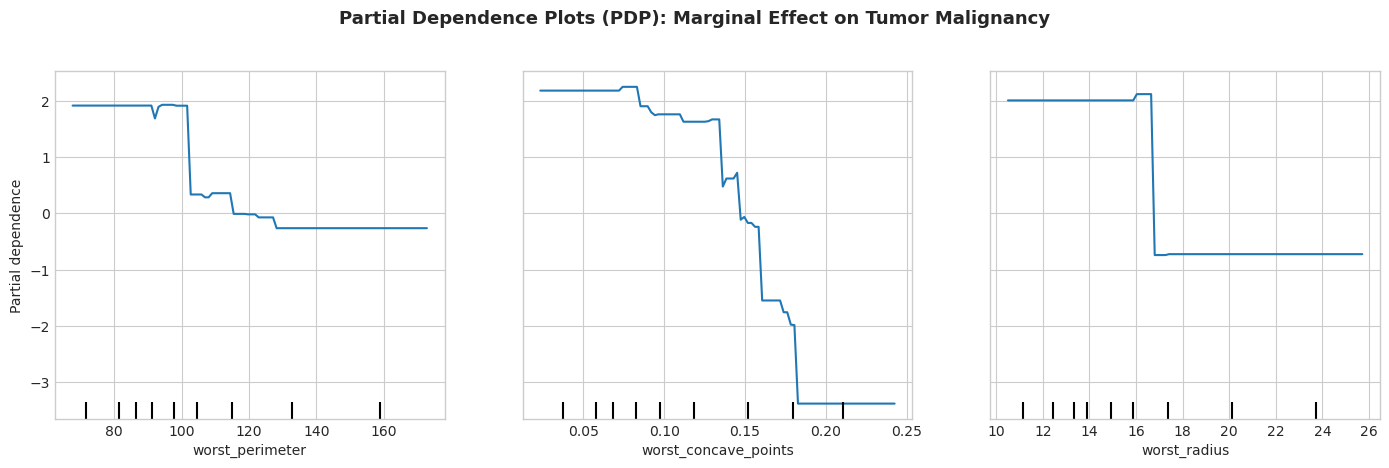

In [7]:
# Generate 1D Partial Dependence Plots for key predictive features using Random Forest (Fast C-recursion)
fig, ax = plt.subplots(figsize=(14, 4.5))

pdp_features = ['worst_perimeter', 'worst_concave_points', 'worst_radius']
display = PartialDependenceDisplay.from_estimator(
    gb_clf,
    X_train,
    features=pdp_features,
    kind='average',
    method='recursion',
    ax=ax
)

plt.suptitle('Partial Dependence Plots (PDP): Marginal Effect on Tumor Malignancy', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


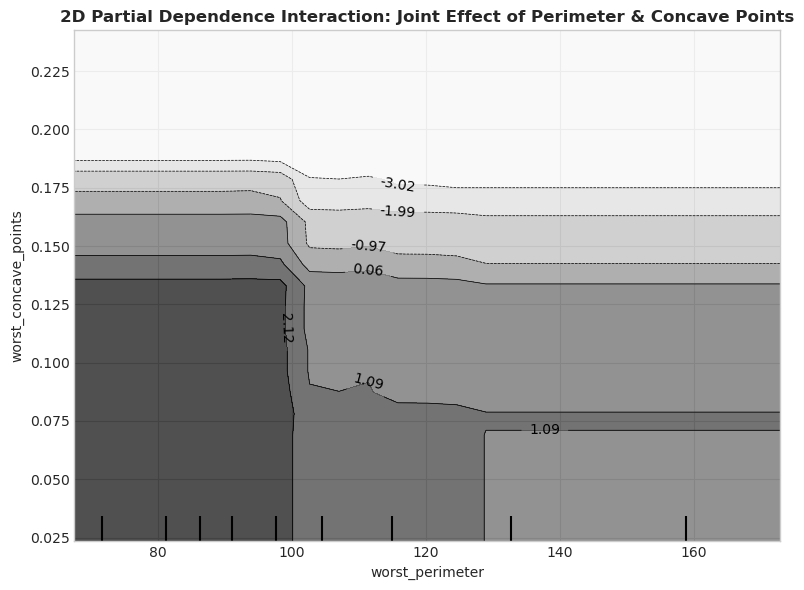

In [8]:
# Generate 2D Partial Dependence Interaction Plot
fig, ax = plt.subplots(figsize=(8, 6))

display_2d = PartialDependenceDisplay.from_estimator(
    gb_clf,
    X_train,
    features=[('worst_perimeter', 'worst_concave_points')],
    kind='average',
    method='recursion',
    grid_resolution=25,
    ax=ax
)

plt.title('2D Partial Dependence Interaction: Joint Effect of Perimeter & Concave Points', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


## 🔍 Section 8: Explainable AI (XAI) — SHAP (SHapley Additive exPlanations)

### 📐 Foundations of Shapley Values:
Originating from cooperative game theory (Lloyd Shapley, Nobel Prize in Economics), the Shapley value represents the **fair marginal contribution** of each feature across all possible subsets of features:

$$\phi_i(x) = \sum_{S \subseteq F \setminus \{i\}} \frac{|S|! (|F| - |S| - 1)!}{|F|!} \left[ f(S \cup \{i\}) - f(S) \right]$$

### 🌟 The Four Core Axioms of SHAP:
1. **Efficiency**: $\sum_{i=1}^M \phi_i(x) = f(x) - E[f(x)]$ (The sum of feature contributions equals the difference between the prediction and the baseline expectation).
2. **Symmetry**: If two features contribute equally across all coalitions, their Shapley values are identical.
3. **Dummy (Null Player)**: A feature that does not change the model output has $\phi_i = 0$.
4. **Additivity**: For ensemble sums $f + g$, $\phi_i(f + g) = \phi_i(f) + \phi_i(g)$.


In [9]:
# Initialize SHAP TreeExplainer on XGBoost
explainer = shap.TreeExplainer(xgb_clf)
shap_values = explainer(X_test)

print(f"SHAP Explainer initialized. Base Expected Value: {explainer.expected_value:.4f}")
print(f"SHAP Values shape: {shap_values.shape}")


SHAP Explainer initialized. Base Expected Value: 0.4717
SHAP Values shape: (143, 30)


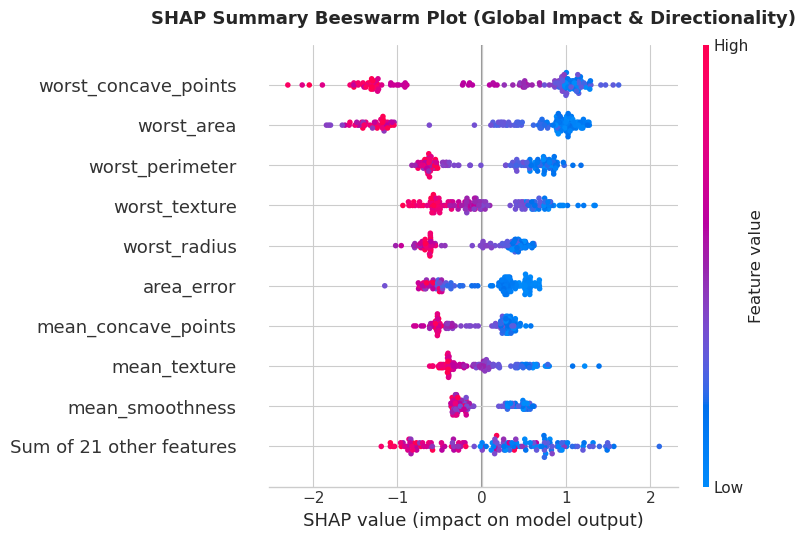

In [10]:
# 1. Global Feature Importance: SHAP Summary Beeswarm Plot
plt.figure(figsize=(10, 6))
shap.plots.beeswarm(shap_values, max_display=10, show=False)
plt.title('SHAP Summary Beeswarm Plot (Global Impact & Directionality)', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


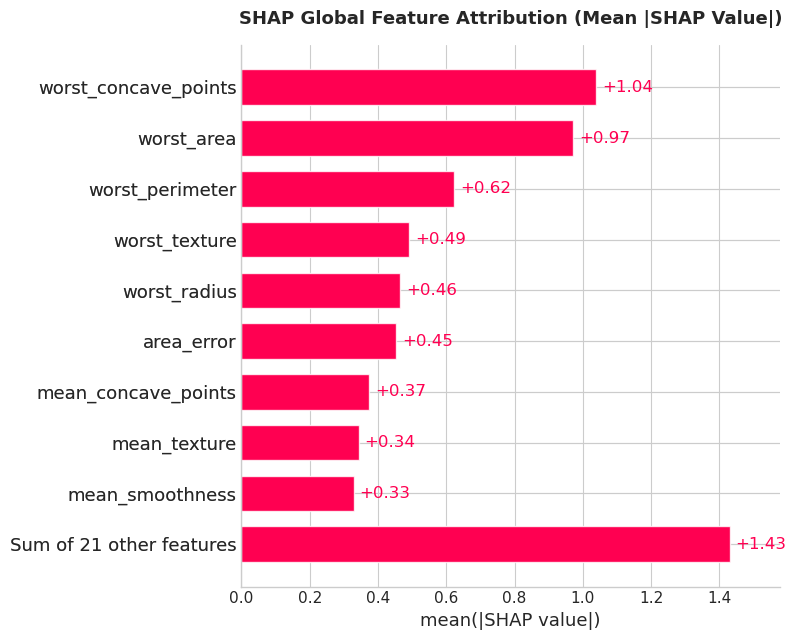

In [11]:
# 2. Global Feature Attribution: SHAP Mean Absolute Value Bar Plot
plt.figure(figsize=(10, 5))
shap.plots.bar(shap_values, max_display=10, show=False)
plt.title('SHAP Global Feature Attribution (Mean |SHAP Value|)', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


Explaining Patient Record #0 (True Class: 1, Predicted: 1):


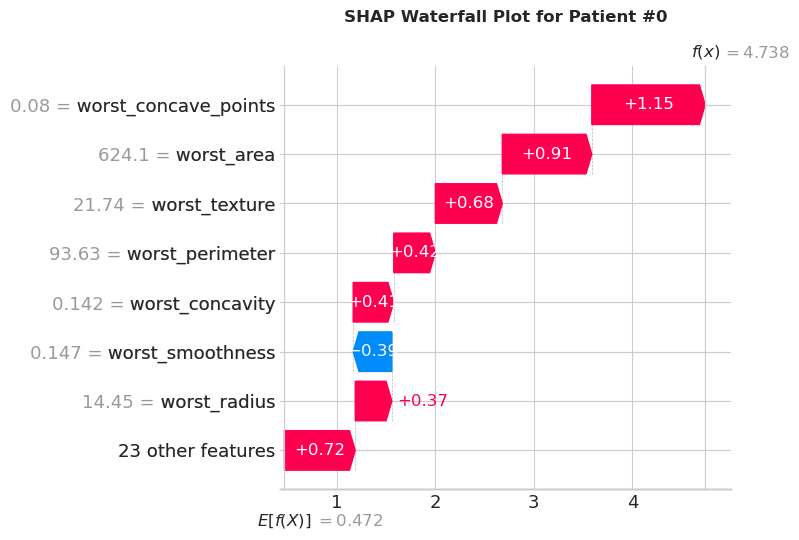

In [12]:
# 3. Local Prediction Explainability: SHAP Waterfall Plot
sample_idx = 0
print(f"Explaining Patient Record #{sample_idx} (True Class: {y_test.iloc[sample_idx]}, Predicted: {xgb_clf.predict(X_test.iloc[[sample_idx]])[0]}):")

plt.figure(figsize=(10, 5.5))
shap.plots.waterfall(shap_values[sample_idx], max_display=8, show=False)
plt.title(f'SHAP Waterfall Plot for Patient #{sample_idx}', fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


## 🎓 Section 9: Senior Machine Learning Interview Master Reference

| # | Question | Senior / Staff ML Engineer Answer |
|---|---|---|
| **1** | **Why doesn't Random Forest overfit as you increase $n\_estimators$?** | By the Law of Large Numbers, averaging $B$ de-correlated trees reduces the variance component of error towards $\rho \sigma^2$ without increasing bias. Adding more trees stabilizes the variance bound; it never increases complexity. |
| **2** | **Why does Boosting overfit if $n\_estimators$ is too high?** | Boosting is a gradient descent process in function space. Each new tree fits the residual errors of the previous ensemble. With infinite iterations, it will eventually memorize noise, mislabeled instances, and outliers. Regularization requires shrinkage ($\eta < 0.1$) and early stopping. |
| **3** | **How does Extra Trees differ fundamentally from Random Forest?** | Extra Trees does not bootstrap (uses the full dataset by default) and picks split thresholds completely at random for each feature candidate rather than optimizing split cutoffs. This lowers variance further and dramatically reduces training time. |
| **4** | **What is the mathematical advantage of XGBoost over standard Gradient Boosting?** | Standard GBDT uses only first-order gradients (pseudo-residuals). XGBoost uses a second-order Taylor expansion (gradients $g_i$ and hessians $h_i$), allowing analytic solution for leaf weights and exact split gain computation with built-in $L_1/L_2$ regularization. |
| **5** | **Why is MDI (Gini Importance) misleading compared to Permutation Importance?** | MDI artificially favors high-cardinality features and continuous variables because they offer more split opportunities, even if their values are pure random noise. Permutation importance tests generalization on unseen test data, eliminating cardinality bias. |
| **6** | **What are the mathematical advantages of SHAP over traditional feature importances?** | SHAP is grounded in cooperative game theory and uniquely guarantees the Efficiency, Symmetry, Dummy, and Additivity axioms. It provides both global attribution (beeswarm) and local explanation (waterfall) with directional sign consistency. |

---
### 🏁 Conclusion
You now have a complete, production-grade mastery of ensemble learning, tree boosting algorithms, and modern Explainable AI (PDP + SHAP).
